# 44 — Question 5: the regions

Do North America, Europe and Asia-Pacific design different aircraft, or the same aircraft at different times?

Sub-questions 5.1, 5.2 and 5.3 of the Labelling Analysis (2026-10-01), the closing section and Table 10. Every path comes from `labelling_analysis.yaml`; equations come from `lib/`, figures and tables from `viz/`.

This notebook reproduces every figure, table and number of chapter 5 of the 45-page document, and compares them with it (`viz.checks`). Chapter 5 reads the twelve classes of the wizard (`topType`, five of them one by one, the rest pooled as *other classes*) and the family F of chapter 3, never the five-class fold, so the class fold of 2026-10-01 (Stopped/Slowed Rotor Wing into Lift + Cruise) moves no number here. The differences from the document's tables are only the display names of 2026-09-28 (Tilt Rotor is printed Tilt Propulsor, propulsive units propulsor units, Combined vectored thrust CVT), which are applied when a table is saved and a figure drawn, never to the numbers. The method is reproduced as the document has it, nothing is changed (METHOD_NOTES.md): the proximity test of 5.3 has no +1 correction and depends on the order of the firms; the lag window of 5.2 is fixed at 2016-2021, the lag verdict cuts at p 0.05 and 0.10, and the trend window of 5.1 starts in 2012 because the author set it after a first reading.

Outputs are written to `<output>/q5_regions/` (figures: pdf, png, csv, json; tables: csv, json). Regenerate this notebook with `python3 notebooks/_build/build_44.py`.

### Chapter 5 — The regions: do North America, Europe and Asia-Pacific design different aircraft, or the same aircraft at different times?

This chapter reads the labelled dataset by the applicant's region on the three variables where the earlier chapters found the variety and the movement: the architecture class, whose shares chapter 3 followed; the propulsor-unit count, since chapter 2 located most of the variety of a design in its propulsion; and whether a propulsor tilts, the other trace chapter 3's drivers moved. Region is asked against exactly those axes.

**Region** is the applicant region of the aircraft's patent: the country of its first assignee, not the office that published it. North America holds 250 aircraft, Europe 177 and Asia-Pacific 186: together 613 of the 627 aircraft (98 %); the 14 from other regions are left out. Figure 21 shows the applicant countries behind the three regions. **Unit, in every other figure: the unique aircraft**, counted once in the window of its priority year; counting the 879 representative patents would weigh a design by how often its firm re-filed it.

## 0. Setup: paths and the analysis unit

The table lists every input this notebook can read, whether it exists and when it last changed. The load raises if a required input is missing.

In [1]:
import sys, pathlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
pd.set_option('display.max_colwidth', 120)
from viz import config, data
cfg = config.load()
config.show(cfg)[['group', 'key', 'exists', 'modified', 'size', 'path']]

,group,key,exists,modified,size,path
0,root,labelled,True,2026-09-25 14:05,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED
1,root,evtolnews,True,2026-09-22 15:12,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS
2,root,reference,True,2026-09-30 18:42,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
3,root,output,True,2026-10-01 19:52,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
4,labelled_dataset,aircraft_labels,True,2026-10-01 16:38,"2,211 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
5,labelled_dataset,figure_labels,True,2026-10-01 16:38,"2,953 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
6,labelled_dataset,label_dictionary,True,2026-10-01 16:38,46 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
7,other_inputs,patent_facts,True,2026-10-01 16:37,"1,595 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
8,other_inputs,trl_per_aircraft,True,2026-09-22 14:41,224 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
9,other_inputs,evtolnews_aircraft,True,2026-09-17 19:41,991 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS/0_source/aircraft.csv


The analysis unit is the representative primary aircraft: wizard-approved, passes the domain gate (no UAV/not-electric/STOL-only tag), one row per aircraft. Counts below must match the document.

In [2]:
ds = data.load_dataset(cfg)
pd.Series(ds.counts, name='count').to_frame()

,count
patents_acquired,1639
patents_wizard_approved,1109
patents_approved,879
patents_gated_out,230
variants_gated_out,257
primary_variants_gated_out,171
patents_analysis,543
approved_variants,963
primary_approved_variants,627
approved_figures,1538


### Tools used below

`frames.base` is the per-aircraft analysis frame (627 rows); `frames.regional_frame` keeps the aircraft of the three regions with their class folded to the five read one by one plus *other*, the propulsor-unit band, whether any propulsor tilts and whether the aircraft belongs to the family F of chapter 3 (`frames.dd_level_keys`). The tables of 5.1 and 5.3 are `frames.region_mix_change` (the trend: `lib.association.spearman_rho_p`), `frames.region_window_mix`, `frames.region_tests` (chi-square: `lib.association.chi2_p_of_columns`) and `frames.region_lean`; 5.2 is `frames.region_years` (`lib.growth.visible_share`), `lib.regional.lag_offsets` (bootstrap), `lag_constancy` (permutation), `region_lag`, `lead_lag` and `lag_offsets_since`; the proximity of firms is `lib.distance.jaffe_proximity`, `lib.distance.proximity_order` and `lib.regional.region_proximity_test`. `viz.checks` compares with the document. `verify` runs one table check and keeps its summary for the final overview; `numbers_check` does the same for the quoted numbers.

In [3]:
import inspect
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
from viz import frames, style, plots, save, checks
from lib import regional, distance, association

style.apply(cfg)
v = frames.base(ds, cfg)                                   # one row per unique aircraft (627)
WIN_NAMES = list(cfg.analysis['windows'])
W, _ = style.size(cfg, 'full')
pct = lambda x: f"{x:.0%}".replace('%', ' %')              # 0.53 -> '53 %'
thin = lambda n: f"{int(n):,}".replace(',', ' ')           # 1 229
pval = lambda p: '< 0.001' if p < 0.001 else f"{p:.3f}" if p < 0.05 else f"{p:.2f}"   # the form of the document's p
yrs = lambda x: '0' if abs(x) == 0 else f"{x:+.1f}".replace('.0', '')                  # +2, -1, +4.5
REGIONS = frames.REGIONS
REG_COL = {r: style.REGIONS[r][0] for r in REGIONS}
ABBR = {'North America': 'NA', 'Europe': 'EU', 'Asia-Pacific': 'AP'}
WSH = {'<= 2011': '≤11', '2012-15': '12–15', '2016-19': '16–19', '2020-23': '20–23', '2024-26 (partial)': '24–26'}
CHECKS, NUMBERS = [], []                                   # summaries kept for the overview at the end

def verify(frame, ref, name=None, doc_wording=False, **kw):
    if doc_wording and 'rename' not in kw:
        kw['rename'] = checks.rename_map(frame)
    r = checks.table(frame, ref, cfg, name=name, **kw)
    CHECKS.append(r)
    display(r.T.rename(columns={0: name or ref}))
    d = checks.detail(r)
    if len(d):
        display(d)

def numbers_check(values, chapter='5', expected=None):
    r = checks.numbers(values, chapter, expected)
    NUMBERS.append(r)
    display(r)

THESIS = {'Tilt Rotor': 'Tilt Propulsor', 'propulsive units': 'propulsor units', 'Combined vectored thrust': 'CVT'}
def thesis_names(frame):
    '''A table as the thesis prints it (the display renames of 2026-09-28): in the column names and in the text cells.'''
    f = frame.rename(columns=lambda c: THESIS.get(c, c) if isinstance(c, str) else c)
    for c in f.columns:
        if f[c].dtype == object:
            f[c] = f[c].map(lambda s: THESIS.get(s, s) if isinstance(s, str) else s)
    return f

CLASSES5 = [c for c in frames.CH5_VARS['class'][1]]                    # SLC TR CVT TW MR other
CLS_WORD = {c: ('other classes' if c == 'other' else 'CVT' if c == 'CVT' else style.cls(c).name) for c in CLASSES5}

### The aircraft of the three regions

`frames.regional_frame` keeps the 613 aircraft of North America, Europe and Asia-Pacific (the 14 of other regions are left out) and adds the columns the chapter reads. A region is the applicant region of the aircraft's patent: the country of its first assignee, not the office that published it. `frames.region_countries` gives the applicant countries behind the regions: per country its region, the patents acquired from it, the representative patents and the unique aircraft; the ten largest by representative patents, then one row for all the others. Checked against the document.

In [4]:
w = frames.regional_frame(ds, v)
rep_n = int(ds.patents['is_representative'].fillna(False).astype(bool).sum())
region_n = v['region3'].value_counts().reindex(REGIONS + ['Other regions'])
display(region_n.rename('unique aircraft').to_frame().T)
assert len(w) == int(region_n[REGIONS].sum()) == 613 and len(v) == 627
rc = frames.region_countries(ds, v)
verify(rc, 'la_region_countries', key=['country'])
save.table(rc, cfg, 'q5', 'tab_region_countries', caption='The applicant countries behind the three regions: patents acquired, representative patents and unique aircraft per country, the ten largest.',
           source='PatSeer (applicant country, priority date) · human labelling')
rc

region3,North America,Europe,Asia-Pacific,Other regions
unique aircraft,250,177,186,14


,la_region_countries
table,la_region_countries
rows (notebook | document),11 | 11
cells compared,66
matched,66
expected differences,0
differences,0
status,match


,country,region,patents acquired,representative patents,unique aircraft,share of representative patents,share of unique aircraft
0,US,North America,651,372,213,0.423,0.340
1,CN,Asia-Pacific,267,127,112,0.144,0.179
2,DE,Europe,188,108,67,0.123,0.107
3,JP,Asia-Pacific,95,66,34,0.075,0.054
4,GB,Europe,43,26,18,0.030,0.029
5,KR,Asia-Pacific,60,23,22,0.026,0.035
6,FR,Europe,58,20,17,0.023,0.027
7,CA,North America,26,18,22,0.020,0.035
8,IT,Europe,28,17,13,0.019,0.021
9,RU,Europe,40,14,16,0.016,0.026


### Figure 21 — the applicant countries behind the regions

Patents acquired and representative patents per country, the ten largest, with each country's unique aircraft; the bar is in the colour of the country's region.

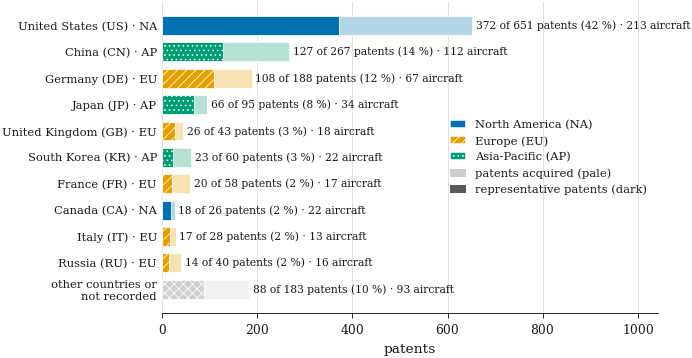

In [5]:
t = rc.iloc[::-1].reset_index(drop=True)                   # the largest at the top
fig, ax = plt.subplots(figsize=(W, 3.3), constrained_layout=True)
for i, r in t.iterrows():
    col = REG_COL.get(r['region'], style.OTHER.color if r['region'] == '' else '#8c8c8c')
    ax.barh(i, r['patents acquired'], 0.72, color=plots.tint(col, 0.3), edgecolor='white', linewidth=0.5, zorder=2)
    ax.barh(i, r['representative patents'], 0.72, color=col, hatch=plots.REGION_HATCH.get(r['region'], 'xxxx'), edgecolor='white', linewidth=0.5, zorder=3)
    ax.text(r['patents acquired'] + 8, i, f"{int(r['representative patents'])} of {int(r['patents acquired'])} patents ({pct(r['share of representative patents'])}) · {int(r['unique aircraft'])} aircraft",
            va='center', ha='left', fontsize=7)
labs = ['other countries or\nnot recorded' if c.startswith('other') else f"{frames.country_name(c)} · {ABBR.get(rg, 'other')}" for c, rg in zip(t['country'], t['region'])]
ax.set_yticks(range(len(t)), labs, fontsize=7.5)
ax.set_xlim(0, float(t['patents acquired'].max()) * 1.6)
ax.set_xlabel('patents'); ax.tick_params(axis='y', length=0); ax.spines[['left']].set_visible(False)
ax.grid(axis='x', color=style.GRID, linewidth=0.5); ax.set_axisbelow(True)
ax.legend(handles=[Patch(facecolor=REG_COL[r], hatch=plots.REGION_HATCH[r], edgecolor='white', label=f"{r} ({ABBR[r]})") for r in REGIONS] +
          [Patch(facecolor=plots.tint('#595959', 0.3), label='patents acquired (pale)'), Patch(facecolor='#595959', label='representative patents (dark)')],
          loc='center right', fontsize=7.5, handlelength=1.4)
plt.show()
save.figure(fig, cfg, 'q5', 'fig_21_region_countries', data=rc,
            caption="the applicant countries behind the three regions: patents acquired and representative patents per country, the ten largest, with each country's unique aircraft.",
            source='PatSeer (applicant country, priority date) · human labelling',
            unit=f"patents (acquired and representative; {thin(rep_n)} representative in all) and unique aircraft ({len(v)}); the ten countries with most representative patents, the rest in one row",
            read="One row per applicant country, the country of the first assignee. The pale bar is every patent acquired from the country, the dark bar the representative patents (one per family), in the colour and hatch of the country's region (NA North America, EU Europe, AP Asia-Pacific). The label reads representative of acquired patents (the country's share of all representative patents), then the country's unique aircraft, the unit of every other figure of the chapter. A country with a few dozen patents weighs little in its region's shares.")
plt.close(fig)

### Chapter 5 numbers (the base of the chapter)

The counts of the opener and of the Method of 5.1, each written the way the document prints it.

In [6]:
N0 = {'c5_all_n': thin(len(v)), 'c5_oth_n': str(int(region_n['Other regions'])), 'c5_three_n': thin(len(w)), 'c5_three_share': pct(len(w) / len(v)),
      'c5_rep_n': thin(rep_n), 'c5_na_n': str(int(region_n['North America'])), 'c5_eu_n': str(int(region_n['Europe'])), 'c5_ap_n': str(int(region_n['Asia-Pacific'])),
      'c5_last': str(regional.LAST_COMPLETE), 'c5_thin': str(frames.CH5_THIN)}
numbers_check(N0)

,name,notebook,document,match
0,c5_all_n,627,627,yes
1,c5_oth_n,14,14,yes
2,c5_three_n,613,613,yes
3,c5_three_share,98 %,98 %,yes
4,c5_rep_n,879,879,yes
5,c5_na_n,250,250,yes
6,c5_eu_n,177,177,yes
7,c5_ap_n,186,186,yes
8,c5_last,2023,2023,yes
9,c5_thin,10,10,yes


In [7]:
# also quoted in the opener's takeaway (not in the document's number list): each against the figure the document prints
rci = rc.set_index('country')
by_region = lambda reg: [frames.COUNTRY_NAMES[c] for c in rc[rc['region'] == reg].sort_values('unique aircraft', ascending=False)['country'] if c in frames.COUNTRY_NAMES]
EXTRA0 = {
    'United States, China, Germany: share of the representative patents': (pct(rc['share of representative patents'].head(3).sum()), '69 %'),
    'the United States alone': (pct(rci.loc['US', 'share of representative patents']), '42 %'),
    'Asia-Pacific is mostly (its two largest countries)': (', '.join(by_region('Asia-Pacific')[:2]), 'China, Japan'),
    'Europe is mostly (its three largest countries)': (', '.join(by_region('Europe')[:3]), 'Germany, United Kingdom, France'),
}
extra0 = pd.DataFrame([{'quoted': k, 'notebook': m, 'document': d, 'match': 'yes' if checks._norm(m) == checks._norm(d) else 'NO'} for k, (m, d) in EXTRA0.items()])
extra0

,quoted,notebook,document,match
0,"United States, China, Germany: share of the representative patents",69 %,69 %,yes
1,the United States alone,42 %,42 %,yes
2,Asia-Pacific is mostly (its two largest countries),"China, Japan","China, Japan",yes
3,Europe is mostly (its three largest countries),"Germany, United Kingdom, France","Germany, United Kingdom, France",yes


## 5.1 — What does each region file, and how has its mix moved since 2012?

#### Method

- **What each region files: Figure 22.** Per region: (i) the class, (ii) the propulsor-unit band, (iii) whether any propulsor tilts. The first bar of each region is **all years together**, the region's whole mix; the bars after it are the priority windows. Each bar is 100 % of the aircraft with the answer recorded (a window under 10 aircraft: blank), a share of the region's own aircraft, not a count.
- **What moved, from 2012.** For each answer, a **Spearman trend test** (statistics box of chapter 1) over 2012-2023, between each aircraft's priority year and the answer (1/0), as for chapter 3's driver traces. ρ is the trend score: +1 when the share always rises with the year, 0 when there is no trend, -1 when it always falls; p is the share of shuffles (years dealt back at random) that give a trend at least as strong, and p < 0.05 is a trend detected. Above each region's chart the two answers with the smallest p are printed, in bold when detected. Before 2012 the regions hold too few aircraft (Europe 15, Asia-Pacific 11): drawn faded. The start year was set by the author after a first reading of the data.

### What each region files, and what moved

`frames.region_window_mix` gives the bars of Figure 22 as numbers: per region, variable (class, propulsor-unit band, whether any propulsor tilts), answer and priority window, the aircraft and the share of the region-window's aircraft whose field is recorded. `frames.region_mix_change` gives, per answer, the aircraft and share in 2012-15, 2016-19 and 2020-23 and the trend over 2012-2023: the Spearman ρ and p (`lib.association.spearman_rho_p`) of the answer (1/0) against each aircraft's own priority year, undefined when the answer never changes. Both are checked against the document (the class and band names print the document's, Tilt Rotor for Tilt Propulsor).

In [8]:
wm = frames.region_window_mix(w, WIN_NAMES)
mc = frames.region_mix_change(w)
verify(wm, 'la_region_window_mix', key=['region', 'variable', 'answer', 'window'])
verify(mc, 'la_region_mix_change', key=['region', 'variable', 'answer'])
save.table(thesis_names(wm), cfg, 'q5', 'tab_region_window_mix', caption='What each region files: the aircraft and share of every answer (class, propulsor units, tilting) in each priority window.',
           source='PatSeer (applicant country, priority date) · human labelling · unit: unique aircraft')
save.table(thesis_names(mc), cfg, 'q5', 'tab_region_mix_change', caption='The trend of every answer over 2012-2023: Spearman ρ of the answer against the aircraft\'s priority year, with its p; the family F as one more answer.',
           source='PatSeer (applicant country, priority date) · human labelling · unit: unique aircraft')
display(thesis_names(mc).head(8)); mc[mc['p'] < 0.05][['region', 'variable', 'answer', 'rho', 'p']]

,la_region_window_mix
table,la_region_window_mix
rows (notebook | document),195 | 195
cells compared,585
matched,585
expected differences,0
differences,0
status,match


,la_region_mix_change
table,la_region_mix_change
rows (notebook | document),42 | 42
cells compared,546
matched,546
expected differences,0
differences,0
status,match


,region,variable,answer,label,aircraft 2012-15,base 2012-15,share 2012-15,aircraft 2016-19,base 2016-19,share 2016-19,aircraft 2020-23,base 2020-23,share 2020-23,aircraft 2012-23,rho,p
0,North America,class,SLC,Lift + Cruise,5,29,0.1724,18,104,0.1731,14,77,0.1818,210,-0.012,0.8682
1,North America,class,TR,Tilt Propulsor,10,29,0.3448,31,104,0.2981,22,77,0.2857,210,-0.048,0.4901
2,North America,class,CVT,CVT,7,29,0.2414,10,104,0.0962,28,77,0.3636,210,0.244,0.0004
3,North America,class,TW,Tilt Wing,4,29,0.1379,18,104,0.1731,5,77,0.0649,210,-0.092,0.1853
4,North America,class,MR,Multirotor,1,29,0.0345,7,104,0.0673,2,77,0.0260,210,-0.030,0.6609
5,North America,class,other,other classes,2,29,0.0690,20,104,0.1923,6,77,0.0779,210,-0.108,0.1201
6,North America,propulsor units,1-3,1-3,14,29,0.4828,23,99,0.2323,11,75,0.1467,203,-0.278,0.0001
7,North America,propulsor units,4,4,8,29,0.2759,20,99,0.2020,13,75,0.1733,203,-0.114,0.1060


,region,variable,answer,rho,p
2,North America,class,CVT,0.244,0.0004
6,North America,propulsive units,1-3,-0.278,0.0001
8,North America,propulsive units,5-6,0.286,0.0000
13,North America,family F,True,0.204,0.0030
21,Europe,propulsive units,4,-0.185,0.0282
23,Europe,propulsive units,7-8,0.205,0.0150
27,Europe,family F,True,0.183,0.0252


### Figure 22 — what each region files, all years together and per priority window

One column per region and one row per variable: (i) the class, (ii) the propulsor units, (iii) whether any propulsor tilts. The first bar of each region is all years together; then one bar per priority window (blank under 10 aircraft). Above each chart, the two answers with the smallest trend p over 2012-2023, in bold when detected.

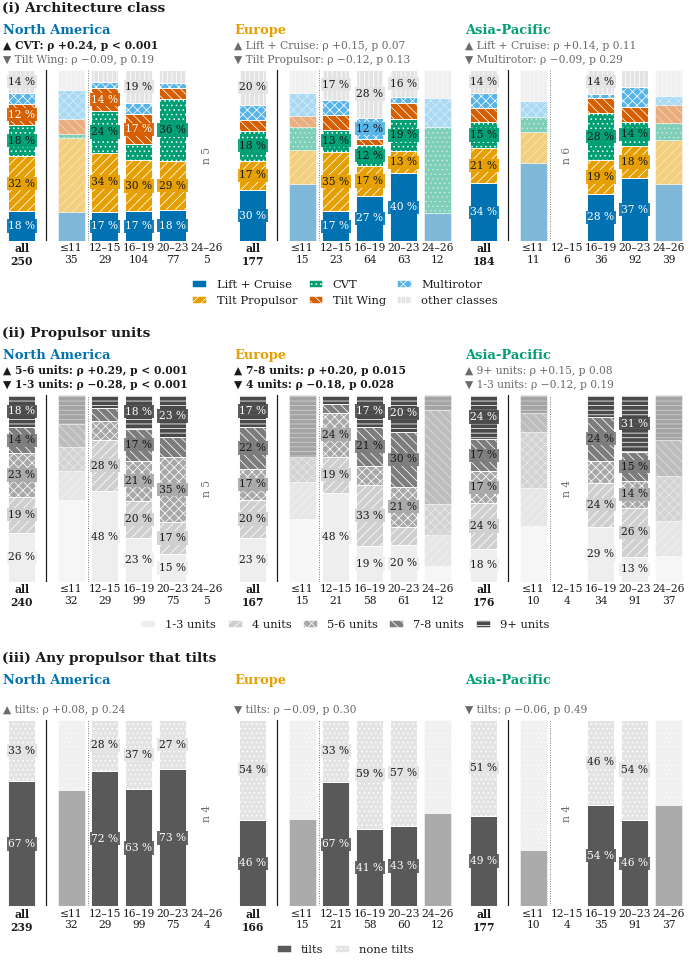

In [9]:
CLS_STYLE = {c: (style.cls(c) if c != 'other' else ('#e3e3e3', '||||')) for c in CLASSES5}
UNIT_ANS = frames.CH5_VARS['propulsive units'][1]
UNIT_STYLE = dict(zip(UNIT_ANS, [('#eeeeee', ''), ('#cfcfcf', '////'), ('#a8a8a8', 'xxxx'), ('#7d7d7d', '\\\\\\\\'), ('#4a4a4a', '----')]))
TILT_STYLE = {True: ('#595959', ''), False: ('#e3e3e3', '....')}
ROWS22 = [('class', '(i) Architecture class', CLASSES5, CLS_STYLE, CLS_WORD),
          ('propulsive units', '(ii) Propulsor units', UNIT_ANS, UNIT_STYLE, {a: f"{a} units" for a in UNIT_ANS}),
          ('tilting unit', '(iii) Any propulsor that tilts', [True, False], TILT_STYLE, {True: 'tilts', False: 'none tilts'})]
OLD, PARTIAL = WIN_NAMES[0], WIN_NAMES[-1]
POS22 = [0.0] + [1.45 + k for k in range(len(WIN_NAMES))]
fig = plt.figure(figsize=(W, 8.8), constrained_layout=True)
subs = fig.subfigures(len(ROWS22), 1)
fig22_data = []
for sub, (var, title, answers, sty, word) in zip(subs, ROWS22):
    col = frames.CH5_VARS[var][0]
    sub.suptitle(title, x=0.005, ha='left', fontsize=9, fontweight='bold')
    axs = sub.subplots(1, 3)
    for ax, reg in zip(axs, REGIONS):
        s = w[w['region3'].eq(reg) & w[col].notna()]
        ns = [int(s['window'].eq(wn).sum()) for wn in WIN_NAMES]
        counts = [[int(s[col].eq(a).sum()) for a in answers]] + [[int(s.loc[s['window'].eq(wn), col].eq(a).sum()) if n >= frames.CH5_THIN else 0 for a in answers] for wn, n in zip(WIN_NAMES, ns)]
        parts = pd.DataFrame(counts, columns=answers)
        fig22_data.append(parts.assign(region=reg, variable=var, bar=['all years'] + WIN_NAMES, n=[len(s)] + ns))
        plots.stack_bars(ax, parts, sty, positions=POS22, width=0.8, partial=[1, len(POS22) - 1], min_label=0.12, fontsize=7, no_label=[1, len(POS22) - 1])
        ax.axvline(0.72, color=style.INK, linewidth=0.8, zorder=4); ax.axvline((POS22[1] + POS22[2]) / 2, color=style.MUTED, linewidth=0.6, linestyle=':', zorder=4)
        for p_, n in zip(POS22[1:], ns):
            if n < frames.CH5_THIN:
                ax.text(p_, 0.5, f"n {n}", ha='center', va='center', fontsize=7, color=style.MUTED, rotation=90)
        ax.set_xticks(POS22, [f"all\n{len(s)}"] + [f"{WSH[wn]}\n{n}" for wn, n in zip(WIN_NAMES, ns)], fontsize=7)
        ax.get_xticklabels()[0].set_fontweight('bold')
        ax.set_ylim(0, 1); ax.set_xlim(-0.55, POS22[-1] + 0.55); ax.set_yticks([]); ax.spines[['left', 'bottom']].set_visible(False); ax.tick_params(length=0, pad=1.5)
        # above the chart: the region, then the trend, the two answers with the smallest p over 2012-2023 ('other classes' is not a class)
        cand = mc[mc['region'].eq(reg) & mc['variable'].eq(var) & mc['answer'].ne('other')]
        cand = cand[cand['answer'].eq('True')] if var == 'tilting unit' else cand
        cand = cand.dropna(subset=['p']).sort_values('p').head(2)
        ax.annotate(reg, xy=(0, 1), xycoords='axes fraction', xytext=(0, 3 + 2 * 9.2), textcoords='offset points', ha='left', va='bottom', fontsize=8.5, fontweight='bold', color=REG_COL[reg])
        for k, (_, r) in enumerate(cand.iloc[::-1].iterrows()):
            lab = 'tilts' if var == 'tilting unit' else (CLS_WORD[r['answer']] if var == 'class' else f"{r['answer']} units")
            sig = r['p'] < 0.05
            ax.annotate(f"{'▲' if r['rho'] > 0 else '▼'} {lab}: ρ {r['rho']:+.2f}, p {pval(r['p'])}".replace('ρ -', 'ρ −'), xy=(0, 1), xycoords='axes fraction', xytext=(0, 3 + 9.2 * k),
                        textcoords='offset points', ha='left', va='bottom', fontsize=7, fontweight='bold' if sig else None, color=style.INK if sig else style.MUTED)
    sub.legend(handles=[Patch(facecolor=(sty[a].color if hasattr(sty[a], 'color') else sty[a][0]), hatch=(sty[a].hatch if hasattr(sty[a], 'hatch') else sty[a][1]), edgecolor='white', label=word[a]) for a in answers],
               loc='outside lower center', ncol=min(len(answers), 3 if var == 'class' else 5), fontsize=7.5, handlelength=1.3, columnspacing=1.0)
plt.show()
fig22_data = pd.concat(fig22_data, ignore_index=True)
save.figure(fig, cfg, 'q5', 'fig_22_region_design', data=fig22_data,
            caption="what each region files, all years together and per priority window: class, propulsor units and tilting, with the trend from 2012 above each region's chart.",
            source='PatSeer (applicant country, priority date) · human labelling',
            unit=f"unique aircraft ({len(w)} of the three regions); each bar is the aircraft of the region (or region-window) whose field is recorded, n under the bar; a window under {frames.CH5_THIN} aircraft is blank",
            read="One column per region, one row per variable. The first bar (bold n) is all years together, the region's whole mix; then one bar per priority window, 2012-15 to 2020-23 and the partial 2024-26; the window up to 2011 and the partial 2024-26 are faded (too few aircraft, or not yet filled). Each bar is 100 % of its aircraft; a segment of 12 % or more prints its share in the bars that are read. Above each chart: the two answers with the smallest p of the Spearman trend test over 2012-2023 (▲ the share rises with the year, ▼ it falls; ρ is +1 when it always rises, 0 when there is no trend, −1 when it always falls); bold = trend detected (p < 0.05). A bar is a share of one region's aircraft, not a count.",
            panels={'(i)': 'architecture class per region and window', '(ii)': 'propulsor-unit band per region and window', '(iii)': 'whether any propulsor tilts, per region and window'})
plt.close(fig)

### 5.1 numbers

In [10]:
wmi = wm.set_index(['region', 'variable', 'answer', 'window'])
mci = mc.set_index(['region', 'variable', 'answer'])
sh = lambda reg, var, ans, win: wmi.loc[(reg, var, str(ans), win), 'share']
allsh = lambda reg, var, ans: wm[(wm['region'] == reg) & (wm['variable'] == var) & (wm['answer'] == str(ans))]['aircraft'].sum() / wm[(wm['region'] == reg) & (wm['variable'] == var) & (wm['answer'] == str(ans))]['base'].sum()
NA, EU, AP = REGIONS
N1 = {'c5_na_cvt_s1215': pct(sh(NA, 'class', 'CVT', '2012-15')), 'c5_na_cvt_s1619': pct(sh(NA, 'class', 'CVT', '2016-19')), 'c5_na_cvt_s2023': pct(sh(NA, 'class', 'CVT', '2020-23')),
      'c5_ap_u9_p': pval(mci.loc[(AP, 'propulsive units', '9+'), 'p']),
      'c5_ap_w1_clas_base': str(int(wmi.loc[(AP, 'class', 'SLC', OLD), 'base'])), 'c5_eu_w1_clas_base': str(int(wmi.loc[(EU, 'class', 'SLC', OLD), 'base']))}
numbers_check(N1)

,name,notebook,document,match
0,c5_na_cvt_s1215,24 %,24 %,yes
1,c5_na_cvt_s1619,10 %,10 %,yes
2,c5_na_cvt_s2023,36 %,36 %,yes
3,c5_ap_u9_p,0.08,0.08,yes
4,c5_ap_w1_clas_base,11,11,yes
5,c5_eu_w1_clas_base,15,15,yes


In [11]:
# also quoted in the takeaway and the region-by-region paragraphs of 5.1 (not in the document's number list): each against the figure the document prints
arrow = lambda reg, var, ans, wins=('2012-15', '2016-19', '2020-23'): ' → '.join(pct(sh(reg, var, ans, x)) for x in wins)
pp = lambda reg, var, ans: pval(mci.loc[(reg, var, str(ans)), 'p'])
late = mc[mc['variable'] == 'class'].groupby('answer')['aircraft 2020-23'].sum()
tilt_sh = [sh(NA, 'tilting unit', 'True', x) for x in ('2012-15', '2016-19', '2020-23')]
EXTRA1 = {
    'all years: North America Tilt Propulsor, Lift + Cruise': (f"{pct(allsh(NA, 'class', 'TR'))}, {pct(allsh(NA, 'class', 'SLC'))}", '32 %, 18 %'),
    'all years: Europe, Asia-Pacific Lift + Cruise': (f"{pct(allsh(EU, 'class', 'SLC'))}, {pct(allsh(AP, 'class', 'SLC'))}", '30 %, 34 %'),
    'all years: aircraft with a tilting propulsor, NA / EU / AP': (' / '.join(pct(allsh(r, 'tilting unit', True)) for r in REGIONS), '67 % / 46 % / 49 %'),
    '2020-23 over the three regions: Lift + Cruise, CVT, Tilt Propulsor (aircraft)': (f"{int(late['SLC'])} / {int(late['CVT'])} / {int(late['TR'])}", '73 / 53 / 47'),
    '2020-23 Lift + Cruise share in North America': (pct(sh(NA, 'class', 'SLC', '2020-23')), '18 %'),
    'North America CVT: ρ, p': (f"{mci.loc[(NA, 'class', 'CVT'), 'rho']:+.2f}, p {pp(NA, 'class', 'CVT')}", '+0.24, p < 0.001'),
    'North America Tilt Propulsor 2012-15 → 2016-19 → 2020-23, p': (f"{arrow(NA, 'class', 'TR')}, p {pp(NA, 'class', 'TR')}", '34 % → 30 % → 29 %, p 0.49'),
    'North America Tilt Propulsor before 2012: share, aircraft': (f"{pct(sh(NA, 'class', 'TR', OLD))} on {int(wmi.loc[(NA, 'class', 'TR', OLD), 'base'])} aircraft", '43 % on 35 aircraft'),
    'North America 1-3 units 2012-15 → 2020-23, p': (f"{arrow(NA, 'propulsive units', '1-3', ('2012-15', '2020-23'))}, p {pp(NA, 'propulsive units', '1-3')}", '48 % → 15 %, p < 0.001'),
    'North America 5-6 units 2012-15 → 2020-23, p': (f"{arrow(NA, 'propulsive units', '5-6', ('2012-15', '2020-23'))}, p {pp(NA, 'propulsive units', '5-6')}", '10 % → 35 %, p < 0.001'),
    'North America tilting share, lowest-highest window': (f"{pct(min(tilt_sh))}-{pct(max(tilt_sh))}", '63 %-73 %'),
    'Europe Lift + Cruise 2012-15 → 2016-19 → 2020-23': (arrow(EU, 'class', 'SLC'), '17 % → 27 % → 40 %'),
    'Europe CVT 2012-15 → 2016-19 → 2020-23': (arrow(EU, 'class', 'CVT'), '13 % → 12 % → 19 %'),
    'Europe Lift + Cruise, CVT: p': (f"{pp(EU, 'class', 'SLC')}, {pp(EU, 'class', 'CVT')}", '0.07, 0.91'),
    'Europe CVT in the partial 2024-26 window: share, aircraft': (f"{pct(sh(EU, 'class', 'CVT', PARTIAL))} on {int(wmi.loc[(EU, 'class', 'CVT', PARTIAL), 'base'])} aircraft", '50 % on 12 aircraft'),
    'Europe 7-8 units 2012-15 → 2016-19 → 2020-23, p': (f"{arrow(EU, 'propulsive units', '7-8')}, p {pp(EU, 'propulsive units', '7-8')}", '5 % → 21 % → 30 %, p 0.015'),
    'Asia-Pacific aircraft in 2012-15': (str(int(wmi.loc[(AP, 'class', 'SLC', '2012-15'), 'base'])), '6'),
    'Asia-Pacific Lift + Cruise 2016-19 → 2020-23': (arrow(AP, 'class', 'SLC', ('2016-19', '2020-23')), '28 % → 37 %'),
    'Asia-Pacific 9 units or more 2016-19 → 2020-23': (arrow(AP, 'propulsive units', '9+', ('2016-19', '2020-23')), '12 % → 31 %'),
    'Asia-Pacific tilting share 2016-19 → 2020-23': (arrow(AP, 'tilting unit', 'True', ('2016-19', '2020-23')), '54 % → 46 %'),
}
extra1 = pd.DataFrame([{'quoted': k, 'notebook': m, 'document': d, 'match': 'yes' if checks._norm(m) == checks._norm(d) else 'NO'} for k, (m, d) in EXTRA1.items()])
extra1

,quoted,notebook,document,match
0,"all years: North America Tilt Propulsor, Lift + Cruise","32 %, 18 %","32 %, 18 %",yes
1,"all years: Europe, Asia-Pacific Lift + Cruise","30 %, 34 %","30 %, 34 %",yes
2,"all years: aircraft with a tilting propulsor, NA / EU / AP",67 % / 46 % / 49 %,67 % / 46 % / 49 %,yes
3,"2020-23 over the three regions: Lift + Cruise, CVT, Tilt Propulsor (aircraft)",73 / 53 / 47,73 / 53 / 47,yes
4,2020-23 Lift + Cruise share in North America,18 %,18 %,yes
5,"North America CVT: ρ, p","+0.24, p < 0.001","+0.24, p < 0.001",yes
6,"North America Tilt Propulsor 2012-15 → 2016-19 → 2020-23, p","34 % → 30 % → 29 %, p 0.49","34 % → 30 % → 29 %, p 0.49",yes
7,"North America Tilt Propulsor before 2012: share, aircraft",43 % on 35 aircraft,43 % on 35 aircraft,yes
8,"North America 1-3 units 2012-15 → 2020-23, p","48 % → 15 %, p < 0.001","48 % → 15 %, p < 0.001",yes
9,"North America 5-6 units 2012-15 → 2020-23, p","10 % → 35 %, p < 0.001","10 % → 35 %, p < 0.001",yes


## 5.2 — Which region moves first on each class, do the others follow, and is North America's recent fall in filings real?

#### Method

- **Aircraft per year: Figure 23 (i).** North America's share of each priority year is printed on its segment.
- **Publication lag.** A patent enters the labelled dataset only once published, and the delay differs by office: priority to publication took a median of 2 years for North America's aircraft of 2016-21 (96 % published in the United States) and 1 for Asia-Pacific's (50 % in China). Recent years therefore show Asia-Pacific more fully. To test whether lag alone moves the regional shares of recent years, each region's count of a year is divided by the part of its aircraft the June 2026 snapshot can already see (read from its own 2016-21 lags) and the shares recomputed.
- **When each region takes up a class: (ii).** A region's median priority year in a class minus that of North America, the region with the most aircraft, taken as the reference; with a 95 % bootstrap interval, on complete years (to 2023) and the five classes with 10 aircraft or more in every region. The median, not the mean, because priority years are bounded and skewed to recent years. An interval that excludes 0 is a difference detected.
- **Sector events** (dotted) are dated company and regulator notices, set beside the regional peaks as hypotheses, never tested as causes.

### Aircraft per year, the publication lag and the regional delays

`frames.region_years` counts the aircraft per priority year and region (North America's share of the year), reads each region's publication lag on its aircraft of 2016-21 and gives the part of a year's aircraft the June 2026 snapshot can already see (`lib.growth.visible_share`: P(lag ≤ k−1) + f · P(lag = k)), then divides each count by it and recomputes the shares. `lib.regional.region_lag` gives the lag itself (median years, the main publication office). `lib.regional.lead_lag` gives the median priority year of each region (aircraft to 2023).

`lib.regional.lag_frame` keeps the classes with at least 5 aircraft in every region (seven; Figure 23 (ii) draws the five with 10 or more), `lag_offsets` the median offset of each region from North America with its 95 % bootstrap interval (2 000 draws, seed 42, resampling inside the class-region cells), `lag_offsets_since` the same on the aircraft of 2016 onward with an *all classes* row, `lag_constancy` the permutation test of whether the lag is the same in every class (mid-ranks of the year, 5 000 permutations); its verdict cuts at p 0.05 and 0.10. All are checked against the document (the class names print the document's: Combined vectored thrust, Tilt Rotor).

In [12]:
ry = frames.region_years(ds, v)
jpub = frames.with_publication(ds, v)
rl = regional.region_lag(jpub)
curves, ll = regional.lead_lag(v, 'region3')
lf = regional.lag_frame(v, class_names=frames.LAG_CLASS_NAMES)
off = regional.lag_offsets(lf)
off16 = regional.lag_offsets_since(v, class_names=frames.LAG_CLASS_NAMES)
lc = regional.lag_constancy(lf, off)
verify(ry, 'la_region_years', key=['priority year', 'region'])
verify(rl, 'la_region_lag', key=['region'])
verify(ll, 'la_lead_lag_region', key=['region3'])
verify(off, 'la_lag_offsets', key=['class', 'region'])
verify(off16, 'la_lag_offsets_2016', key=['class', 'region'])
verify(lc, 'la_lag_constancy', name='la_lag_constancy (the numbers; the verdict text is wording)', columns=['df', 'F (on ranks)', 'p (parametric)', 'p (permutation)', 'partial η²', 'permutations', 'aircraft', 'classes', 'p (Holm, across the two regions)'])
print('lag verdict:', lc.attrs['verdict_code'], lc.attrs['verdict_regions'])
for name, fr, cap in (('tab_region_years', ry, 'Aircraft per priority year and region, the part of them the June 2026 snapshot can already see, and the shares corrected for publication lag.'),
                      ('tab_region_lag', rl, 'The publication lag of each region\'s aircraft of 2016-21: median years, main publication office and the share published within 0-3 years.'),
                      ('tab_lead_lag_region', ll, 'The priority year by which each region had filed 25, 50 and 75 % of its aircraft (to 2023).'),
                      ('tab_lag_offsets', off, 'Each region\'s offset in median priority year against North America, by class, with its 95 % bootstrap interval.'),
                      ('tab_lag_offsets_2016', off16, 'The same offsets on the aircraft of priority year 2016 onward, with an all-classes row.'),
                      ('tab_lag_constancy', lc, 'Is the regional lag the same in every class: interaction, region and class tests on the mid-ranks of the priority year.')):
    save.table(thesis_names(fr), cfg, 'q5', name, caption=cap, source='PatSeer (applicant country, priority and publication date) · human labelling · unit: unique aircraft')
display(ry[ry['priority year'] >= 2020].pivot(index='priority year', columns='region', values='aircraft')); thesis_names(off)

,la_region_years
table,la_region_years
rows (notebook | document),45 | 45
cells compared,225
matched,225
expected differences,0
differences,0
status,match


,la_region_lag
table,la_region_lag
rows (notebook | document),3 | 3
cells compared,24
matched,24
expected differences,0
differences,0
status,match


,la_lead_lag_region
table,la_lead_lag_region
rows (notebook | document),3 | 3
cells compared,18
matched,18
expected differences,0
differences,0
status,match


,la_lag_offsets
table,la_lag_offsets
rows (notebook | document),21 | 21
cells compared,105
matched,105
expected differences,0
differences,0
status,match


,la_lag_offsets_2016
table,la_lag_offsets_2016
rows (notebook | document),18 | 18
cells compared,108
matched,108
expected differences,0
differences,0
status,match


,la_lag_constancy (the numbers; the verdict text is wording)
table,la_lag_constancy (the numbers; the verdict text is wording)
rows (notebook | document),5 | 5
cells compared,45
matched,45
expected differences,0
differences,0
status,match


lag verdict: consistent []


region,Asia-Pacific,Europe,North America
priority year,,,
2020,35,13,19
2021,18,22,32
2022,18,14,16
2023,21,14,10
2024,21,12,5
2025,16,0,0
2026,2,0,0


,class,region,aircraft,median priority year,offset vs North America (years),95 % low,95 % high
0,CVT,North America,46,2021.0,0.0,-2.0,1.5
1,CVT,Europe,25,2019.0,-2.0,-3.0,1.0
2,CVT,Asia-Pacific,24,2020.0,-1.0,-3.0,1.0
3,Hoverbike,North America,5,2017.0,0.0,-1.0,1.0
4,Hoverbike,Europe,7,2017.0,0.0,-2.0,2.0
5,Hoverbike,Asia-Pacific,5,2015.0,-2.0,-6.0,2.0
6,Lift + Cruise,North America,43,2018.0,0.0,-2.0,2.0
7,Lift + Cruise,Europe,51,2019.0,1.0,0.0,4.0
8,Lift + Cruise,Asia-Pacific,49,2020.0,2.0,1.0,4.0
9,Multirotor,North America,16,2016.0,0.0,-12.0,11.5


### Figure 23 — when each region files

(i) The unique aircraft per priority year and applicant region, with North America's share of the year on its segment, the years the snapshot has not fully seen faded, the dated sector events under the bars and each region's median year in the legend. (ii) How many years after North America Europe and Asia-Pacific file each class: the difference of the median priority years with its 95 % bootstrap interval, for the five classes with 10 aircraft or more in every region.

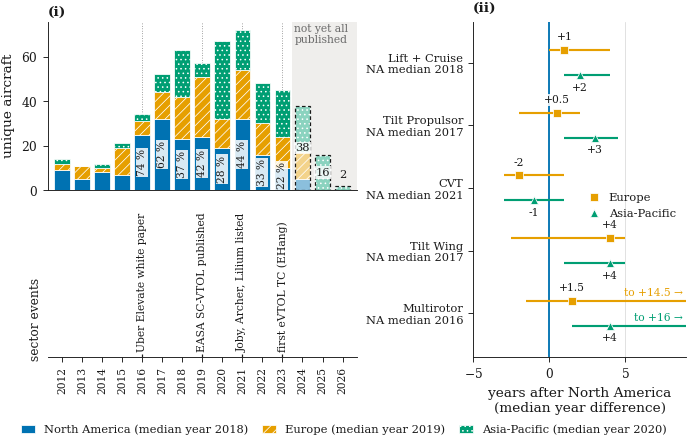

In [13]:
ev_dates = ['2016-10-27', '2019-07-02', '2021-08-11', '2023-10-13']       # the four events the document draws (Uber Elevate paper, EASA SC-VTOL, listings, EHang type certificate)
ev_all = frames.sector_events(cfg, frames.snapshot_date(ds))
events = ev_all[ev_all['date'].dt.strftime('%Y-%m-%d').isin(ev_dates)].reset_index(drop=True)
assert len(events) == 4, events
tab23 = ry.pivot(index='priority year', columns='region', values='aircraft')[REGIONS]
share23 = ry.pivot(index='priority year', columns='region', values='share of the year')[REGIONS]
years = list(tab23.index)
incomplete = [y for y in years if y > regional.LAST_COMPLETE]
med = ll.set_index('region3')['50 %']
classes23 = [c for c in style.CLASS_ORDER if frames.LAG_CLASS_NAMES[c] in set(off['class']) and all((off[(off['class'] == frames.LAG_CLASS_NAMES[c])]['aircraft'] >= 10))]
fig = plt.figure(figsize=(W, 4.1), constrained_layout=True)
gs = fig.add_gridspec(2, 2, width_ratios=[1.45, 1.0], height_ratios=[3.0, 1.35])
a1, strip, a2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[:, 1])
plots.region_stack(a1, tab23, incomplete=incomplete)
first_inc = years.index(incomplete[0])
a1.axvspan(first_inc - 0.5, len(years) - 0.3, color=plots.FEW_FILL, zorder=0, linewidth=0)
a1.text(first_inc - 0.4, a1.get_ylim()[1] * 0.99, 'not yet all\npublished', va='top', fontsize=7, color=style.MUTED)
for i, y in enumerate(years):                                                     # North America's share of the year, on its segment
    n_na = tab23.loc[y, NA]
    if y >= 2016 and y <= regional.LAST_COMPLETE and n_na >= 8:
        a1.text(i, n_na / 2 if n_na >= 12 else 0.4, pct(share23.loc[y, NA]), ha='center', va='center' if n_na >= 12 else 'bottom', rotation=90, fontsize=7, color=style.INK, zorder=6, bbox=dict(boxstyle='square,pad=0.1', fc='white', ec='none', alpha=0.85))
a1.set_xticks([]); a1.set_ylabel('unique aircraft')
h, _l = a1.get_legend_handles_labels()
fig.legend(h, [f"{r} (median year {int(med[r])})" for r in REGIONS], loc='outside lower center', ncol=3, fontsize=7.5, handlelength=1.2, columnspacing=1.2); style.mark(a1, '(i)')
plots.event_strip(strip, events.assign(year=events['year']), years, parent=a1)
strip.set_xlim(a1.get_xlim()); strip.set_xticks(range(len(years)), [str(y) for y in years], rotation=90, fontsize=7)
# (ii) years after North America, per class: the interval is cut at the axis edge and its end value printed
XMAX = 9.0
ypos = np.arange(len(classes23))
for dy, reg, side in ((-0.2, 'Europe', 1), (0.2, 'Asia-Pacific', -1)):
    s = off[off['region'].eq(reg)].set_index('class').reindex([frames.LAG_CLASS_NAMES[c] for c in classes23])
    o, lo, hi = s['offset vs North America (years)'].to_numpy(), s['95 % low'].to_numpy(), s['95 % high'].to_numpy()
    sty = style.REGIONS[reg]
    a2.hlines(ypos + dy, lo, np.minimum(hi, XMAX), color=sty[0], linewidth=1.4, zorder=3)
    a2.plot(o, ypos + dy, linestyle='none', marker=sty[1], markersize=5, color=sty[0], markeredgecolor='white', markeredgewidth=0.5, zorder=4, label=reg)
    for yy, oo, hh in zip(ypos + dy, o, hi):
        a2.annotate(yrs(oo), (oo, yy), xytext=(0, 5 * side), textcoords='offset points', ha='center', va='bottom' if side == 1 else 'top', fontsize=7, color=style.INK, bbox=dict(boxstyle='square,pad=0.1', fc='white', ec='none', alpha=0.85), zorder=6)
        if hh > XMAX:
            a2.annotate(f"to {yrs(hh)} →", (XMAX, yy), xytext=(-2, 2), textcoords='offset points', ha='right', va='bottom', fontsize=7, color=sty[0])
a2.axvline(0, color=REG_COL[NA], linewidth=1.2, zorder=2)
na_med = off[off['region'].eq(NA)].set_index('class')['median priority year']
a2.set_yticks(ypos, [f"{CLS_WORD[c]}\nNA median {int(na_med[frames.LAG_CLASS_NAMES[c]])}" for c in classes23], fontsize=7.5)
a2.set_ylim(len(classes23) - 0.3, -0.65); a2.set_xlim(-5, XMAX); a2.set_xlabel('years after North America\n(median year difference)')
a2.grid(axis='x', color=style.GRID, linewidth=0.5); a2.set_axisbelow(True)
a2.legend(loc='center right', fontsize=7.5, handlelength=1.0, bbox_to_anchor=(1.0, 0.45)); style.mark(a2, '(ii)')
plt.show()
fig23_data = pd.concat([ry.assign(panel='(i)'), off.assign(panel='(ii)')], ignore_index=True)
save.figure(fig, cfg, 'q5', 'fig_23_region_timing', data=fig23_data,
            caption='when each region files: aircraft per priority year and region against dated sector events, and how many years after North America Europe and Asia-Pacific file each class.',
            source='PatSeer (applicant country, priority and publication date) · human labelling · sector events: the author\'s dated list (checked 2026-09-23)',
            unit=f"unique aircraft per priority year ({int(tab23.to_numpy().sum())} of the three regions, 2012-2026); (ii) priority years to {regional.LAST_COMPLETE}, the {len(classes23)} classes with 10 aircraft or more in every region",
            read="(i) Stacked bars: aircraft per priority year by region; the number on the North America segment is its share of that year's aircraft of the three regions (years from 2016 with 8 aircraft or more). Faded, dashed and shaded: the years the snapshot of June 2026 has not fully seen (2024 onward). Dotted lines: dated sector events (company and regulator notices), set beside the peaks as hypotheses, never tested as causes. The legend gives each region's median priority year to 2023. (ii) One row per class. Dot: the region's median priority year minus North America's (+ = the region files later); bar: its 95 % bootstrap interval, an interval that excludes 0 is a difference detected; an interval running past +9 is cut at the edge and its end printed. Under the class: North America's median year.",
            panels={'(i)': 'aircraft per priority year and applicant region', '(ii)': 'years after North America, per class'})
plt.close(fig)

### 5.2 numbers

In [14]:
rli, lli = rl.set_index('region'), ll.set_index('region3')
mnames = {'US': 'United States', 'CN': 'China', 'DE': 'Germany', 'EP': 'European Patent Office'}
a_, b_ = sorted((int(lli.loc[EU, '50 %'] - lli.loc[NA, '50 %']), int(lli.loc[AP, '50 %'] - lli.loc[NA, '50 %'])))
numw = {0: 'zero', 1: 'one', 2: 'two', 3: 'three', 4: 'four'}
offi = off.set_index(['class', 'region'])
ap_old = [offi.loc[(frames.LAG_CLASS_NAMES[c], AP), 'offset vs North America (years)'] for c in ('SLC', 'TR', 'TW')]
N2 = {'c5_na_median': str(int(lli.loc[NA, '50 %'])), 'c5_eu_median': str(int(lli.loc[EU, '50 %'])), 'c5_ap_median': str(int(lli.loc[AP, '50 %'])),
      'c5_follow_years': f"{numw.get(a_, a_)} and {numw.get(b_, b_)} years" if a_ != b_ else f"{numw.get(a_, a_)} years",
      'c5_na_lag': str(int(rli.loc[NA, 'median lag (years)'])), 'c5_ap_lag': str(int(rli.loc[AP, 'median lag (years)'])),
      'c5_na_off': mnames.get(rli.loc[NA, 'main office'], rli.loc[NA, 'main office']), 'c5_ap_off': mnames.get(rli.loc[AP, 'main office'], rli.loc[AP, 'main office']),
      'c5_na_off_share': pct(rli.loc[NA, 'its share']), 'c5_ap_off_share': pct(rli.loc[AP, 'its share']),
      'c5_ap_delay_range': f"{int(min(ap_old))}-{int(max(ap_old))}" if min(ap_old) != max(ap_old) else f"{int(min(ap_old))}"}
numbers_check(N2)

,name,notebook,document,match
0,c5_na_median,2018,2018,yes
1,c5_eu_median,2019,2019,yes
2,c5_ap_median,2020,2020,yes
3,c5_follow_years,one and two years,one and two years,yes
4,c5_na_lag,2,2,yes
5,c5_ap_lag,1,1,yes
6,c5_na_off,United States,United States,yes
7,c5_ap_off,China,China,yes
8,c5_na_off_share,96 %,96 %,yes
9,c5_ap_off_share,50 %,50 %,yes


In [15]:
# also quoted in the takeaway and the hypotheses of 5.2 (not in the document's number list): each against the figure the document prints
ryi = ry.set_index(['priority year', 'region'])
interval = lambda tab, c, reg: f"{yrs(tab.loc[(frames.LAG_CLASS_NAMES[c], reg), 'offset vs North America (years)'])} ({yrs(tab.loc[(frames.LAG_CLASS_NAMES[c], reg), '95 % low'])} to {yrs(tab.loc[(frames.LAG_CLASS_NAMES[c], reg), '95 % high'])})"
off16i = off16.set_index(['class', 'region'])
med16 = off16[off16['class'] == 'all classes'].set_index('region')['median priority year']
peak = lambda reg: ry[(ry['region'] == reg) & (ry['priority year'] <= regional.LAST_COMPLETE)].sort_values('aircraft', ascending=False, kind='stable').iloc[0]
late_y = ry[ry['priority year'] > regional.LAST_COMPLETE]
last2 = ry[ry['priority year'] > regional.LAST_COMPLETE + 1]
EXTRA2 = {
    "North America's share of the year, 2021 → 2023": (f"{pct(ryi.loc[(2021, NA), 'share of the year'])} → {pct(ryi.loc[(2023, NA), 'share of the year'])}", '44 % → 22 %'),
    "North America's share corrected for lag, 2023 and 2024": (f"{pct(ryi.loc[(2023, NA), 'share corrected for publication lag'])} and {pct(ryi.loc[(2024, NA), 'share corrected for publication lag'])}", '22 % and 14 %'),
    'the part of the 2023 aircraft the snapshot sees, lowest-highest region': (f"{pct(ry[ry['priority year'] == 2023]['visible at the snapshot'].min())}-{pct(ry[ry['priority year'] == 2023]['visible at the snapshot'].max())}", '87 %-92 %'),
    "North America's aircraft, 2021 → 2023": (f"{int(ryi.loc[(2021, NA), 'aircraft'])} → {int(ryi.loc[(2023, NA), 'aircraft'])}", '32 → 10'),
    'Asia-Pacific aircraft a year, 2021-2023 (lowest-highest)': (f"{int(ry[(ry['region'] == AP) & ry['priority year'].between(2021, 2023)]['aircraft'].min())}-{int(ry[(ry['region'] == AP) & ry['priority year'].between(2021, 2023)]['aircraft'].max())}", '18-21'),
    "North America's share of the partial 2024-26 window": (pct(late_y.groupby('region')['aircraft'].sum()[NA] / late_y['aircraft'].sum()), '9 %'),
    'aircraft of 2025-26: Asia-Pacific, the other regions': (f"{int(last2[last2['region'] == AP]['aircraft'].sum())}, {int(last2[last2['region'] != AP]['aircraft'].sum())}", '18, 0'),
    'the part of the 2025 aircraft the snapshot sees: Asia-Pacific, North America': (f"{pct(ryi.loc[(2025, AP), 'visible at the snapshot'])}, {pct(ryi.loc[(2025, NA), 'visible at the snapshot'])}", '46 %, 21 %'),
    'Asia-Pacific on Lift + Cruise (offset, interval)': (interval(offi, 'SLC', AP), '+2 (+1 to +4)'),
    'Asia-Pacific on Tilt Propulsor': (interval(offi, 'TR', AP), '+3 (+1 to +4.5)'),
    'Asia-Pacific on Tilt Wing': (interval(offi, 'TW', AP), '+4 (+1 to +5)'),
    'Asia-Pacific on CVT': (interval(offi, 'CVT', AP), '-1 (-3 to +1)'),
    "North America's median year on CVT": (str(int(offi.loc[(frames.LAG_CLASS_NAMES['CVT'], NA), 'median priority year'])), '2021'),
    'every European interval reaches zero': ('yes' if all((offi.loc[(frames.LAG_CLASS_NAMES[c], EU), '95 % low'] <= 0 <= offi.loc[(frames.LAG_CLASS_NAMES[c], EU), '95 % high']) for c in classes23) else 'no', 'yes'),
    'does the delay differ from class to class (permutation p)': (pval(lc.iloc[0]['p (permutation)']), '0.15'),
    'median priority year on the aircraft of 2016 onward: NA, EU, AP': (f"{int(med16[NA])}, {int(med16[EU])}, {int(med16[AP])}", '2019, 2019, 2020'),
    '2016 onward, Asia-Pacific on Tilt Propulsor': (interval(off16i, 'TR', AP), '+2 (0 to +4)'),
    '2016 onward, Asia-Pacific on Lift + Cruise': (interval(off16i, 'SLC', AP), '+1 (0 to +3)'),
    '2016 onward, Asia-Pacific on Tilt Wing': (interval(off16i, 'TW', AP), '+3 (0 to +4)'),
    "Europe's lead on CVT, all years → 2016 onward": (f"{yrs(offi.loc[(frames.LAG_CLASS_NAMES['CVT'], EU), 'offset vs North America (years)'])} → {yrs(off16i.loc[(frames.LAG_CLASS_NAMES['CVT'], EU), 'offset vs North America (years)'])}", '-2 → -1'),
    'North America files most in (year, aircraft)': (f"{int(peak(NA)['priority year'])} ({int(peak(NA)['aircraft'])})", '2017 (32)'),
    'Europe files most in (year, aircraft)': (f"{int(peak(EU)['priority year'])} ({int(peak(EU)['aircraft'])})", '2019 (27)'),
    'Asia-Pacific files most in (year, aircraft)': (f"{int(peak(AP)['priority year'])} ({int(peak(AP)['aircraft'])})", '2020 (35)'),
}
extra2 = pd.DataFrame([{'quoted': k, 'notebook': m, 'document': d, 'match': 'yes' if checks._norm(m) == checks._norm(d) else 'NO'} for k, (m, d) in EXTRA2.items()])
extra2

,quoted,notebook,document,match
0,"North America's share of the year, 2021 → 2023",44 % → 22 %,44 % → 22 %,yes
1,"North America's share corrected for lag, 2023 and 2024",22 % and 14 %,22 % and 14 %,yes
2,"the part of the 2023 aircraft the snapshot sees, lowest-highest region",87 %-92 %,87 %-92 %,yes
3,"North America's aircraft, 2021 → 2023",32 → 10,32 → 10,yes
4,"Asia-Pacific aircraft a year, 2021-2023 (lowest-highest)",18-21,18-21,yes
5,North America's share of the partial 2024-26 window,9 %,9 %,yes
6,"aircraft of 2025-26: Asia-Pacific, the other regions","18, 0","18, 0",yes
7,"the part of the 2025 aircraft the snapshot sees: Asia-Pacific, North America","46 %, 21 %","46 %, 21 %",yes
8,"Asia-Pacific on Lift + Cruise (offset, interval)",+2 (+1 to +4),+2 (+1 to +4),yes
9,Asia-Pacific on Tilt Propulsor,+3 (+1 to +4.5),+3 (+1 to +4.5),yes


## 5.3 — Do the regions converge on the same design, and does any lean rest on one firm?

#### Method

- **Convergence: Figure 24 (i).** Each region's share of aircraft in the family F of chapter 3 (Lift + Cruise, plus the CVT whose tilting part is a propulsor set on a fixed wing: the dominant design of 3.2), in 2012-15, 2016-19 and 2020-23. A chi-square test of region against F asks whether the regions differ in each window; the same test is run on the propulsor-unit band of Figure 22. Whether a region's F share rises over 2012-2023 is read with the Spearman trend test of 5.1.
- **One firm or the region: (ii).** The labelled dataset's largest filer, Bell / Textron, holds 60 of North America's 250 aircraft and 27 of its 80 Tilt Propulsor. Each region's share with a tilting propulsor and its Tilt Propulsor share are compared (chi-square, all years), with and without that firm.
- **Firms of one region: (iii).** For the 16 firms with 5 aircraft or more, the **proximity** of two firms is the cosine of their class-share profiles: 1 = the same mix, 0 = no class in common. Pairs from the same region are set against pairs from different regions; p is a permutation test shuffling the region labels over the firms. *Unit:* the firm pair, because the question is whether a firm resembles its neighbours.

### Do the regions converge, does a lean rest on one firm, are firms of one region alike

`frames.region_lean` gives, per region, its largest filer, the share of its aircraft with a tilting propulsor and its Tilt Rotor share (both also without that filer) and the family F share in each window from 2012; `frames.region_tests` the chi-square p (`lib.association.chi2_p_of_columns`) of region against each measure, over all years and in each window, with and without Bell / Textron. `frames.region_firm_proximity` builds the proximity of the 16 firms with 5 aircraft or more (`lib.distance.jaffe_proximity`: the cosine of two class-share profiles), the firms in region blocks and, inside a block, in the clustered order of `lib.distance.proximity_order`; `lib.regional.region_pair_summary` gives the mean of every region pair and `lib.regional.region_proximity_test` the permutation p that two firms of one region are closer than two of different regions (10 000 shuffles of the region labels over the firms, seed 42, one-sided, no +1 correction). All are checked against the document.

In [16]:
ln = frames.region_lean(w)
ts = frames.region_tests(w)
mprox, preg = frames.region_firm_proximity(v)
pairs_ = regional.region_pair_summary(mprox.to_numpy(), preg.to_numpy())
px = regional.region_proximity_test(mprox.to_numpy(), preg.to_numpy())
pxt = pd.DataFrame([{'firms': len(preg), 'minimum aircraft per firm': frames.FIRM_MIN, 'same-region pairs': px['same_pairs'], 'same-region mean': px['same_mean'],
                     'different-region pairs': px['different_pairs'], 'different-region mean': px['different_mean'], 'p (permutation)': px['p'], 'draws': px['draws']}])
verify(ln, 'la_region_lean', key=['region'])
verify(ts, 'la_region_tests', key=['measure', 'period', 'filers'])
verify(pairs_, 'la_proximity_region', key=['region pair'])
verify(pxt, 'la_region_proximity_test')
for name, fr, cap in (('tab_region_lean', ln, 'Per region: its largest filer, the share of its aircraft with a tilting propulsor and its Tilt Rotor share, with and without that filer, and the family F share per window.'),
                      ('tab_region_tests', ts, 'Chi-square test of region against each measure, over all years and in each window from 2012, with all filers and without North America\'s largest.'),
                      ('tab_proximity_region', pairs_, 'The mean proximity of the firm pairs of each region pair (the 16 firms with 5 aircraft or more).'),
                      ('tab_region_proximity_test', pxt, 'Permutation test: are two firms of one region closer than two firms of different regions.')):
    save.table(thesis_names(fr), cfg, 'q5', name, caption=cap, source='PatSeer (applicant country, assignee, priority date) · human labelling · unit: unique aircraft; the firm pair for the proximity')
display(thesis_names(ln).T.head(14)); ts[ts['period'] == 'all years']

,la_region_lean
table,la_region_lean
rows (notebook | document),3 | 3
cells compared,60
matched,60
expected differences,0
differences,0
status,match


,la_region_tests
table,la_region_tests
rows (notebook | document),40 | 40
cells compared,80
matched,80
expected differences,0
differences,0
status,match


,la_proximity_region
table,la_proximity_region
rows (notebook | document),6 | 6
cells compared,36
matched,36
expected differences,0
differences,0
status,match


,la_region_proximity_test
table,la_region_proximity_test
rows (notebook | document),1 | 1
cells compared,8
matched,8
expected differences,0
differences,0
status,match


,0,1,2
region,North America,Europe,Asia-Pacific
aircraft,250,177,186
largest filer,Bell / Textron,Airbus,Shenfeng Aviation
its aircraft,60,20,10
its Tilt Rotor aircraft,27,0,0
Tilt Rotor aircraft,80,30,38
its tilting aircraft,52,3,3
tilting aircraft,160,77,86
tilting share,0.6695,0.4639,0.4859
tilting share without it,0.6,0.5068,0.494


,measure,period,filers,aircraft,"p (chi-square, region)"
0,class mix (five classes + other),all years,all filers,611,0.0003
1,class mix (five classes + other),all years,without Bell / Textron,551,0.1019
8,propulsive-unit band,all years,all filers,583,0.0720
9,propulsive-unit band,all years,without Bell / Textron,524,0.3708
16,any tilting unit,all years,all filers,582,0.0000
17,any tilting unit,all years,without Bell / Textron,523,0.0232
24,Tilt Rotor,all years,all filers,611,0.0007
25,Tilt Rotor,all years,without Bell / Textron,551,0.0354
32,family F,all years,all filers,611,0.0181
33,family F,all years,without Bell / Textron,551,0.1212


### Figure 24 — whether the regions converge on family F, whether the tilting lean rests on one firm, whether firms of one region are alike

(i) Each region's share of the family F of chapter 3 in each window from 2012, with the chi-square p of the regional difference in each window. (ii) The share with a tilting propulsor and the Tilt Propulsor share per region, North America also without its largest filer. (iii) The proximity of the firms' class profiles, within and across regions.

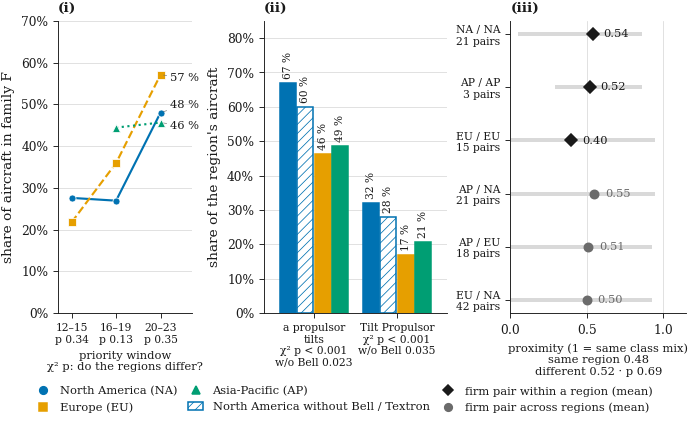

In [17]:
def tp(measure, period, filers='all filers'):
    return float(ts[(ts['measure'] == measure) & (ts['period'] == period) & (ts['filers'] == filers)]['p (chi-square, region)'].iloc[0])
big = ts.attrs['left_out']
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(W, 3.9), constrained_layout=True, gridspec_kw={'width_ratios': [0.95, 1.3, 1.25]})
# (i) family F per window from 2012: a window under 10 aircraft of the region is not drawn
xw = np.arange(len(frames.CH5_WINS))
ends = []
for _, r in ln.iterrows():
    reg = r['region']; sty = style.REGIONS[reg]
    ys = np.array([r[f"F share {x}"] for x in frames.CH5_WINS]); okw = np.array([r[f"F base {x}"] >= frames.CH5_THIN for x in frames.CH5_WINS])
    a1.plot(xw[okw], ys[okw], color=sty[0], linestyle=sty[2], marker=sty[1], markersize=4.6, linewidth=1.4, markeredgecolor='white', markeredgewidth=0.5, zorder=3)
    ends.append((ys[-1], reg))
ends.sort()
plots.end_labels(a1, xw[-1], [e[0] for e in ends], [pct(e[0]) for e in ends], [REG_COL[e[1]] for e in ends], gap=0.05, dx_pt=6, fontsize=7.5)
a1.set_xticks(xw, [f"{WSH[x]}\np {pval(tp('family F', x))}" for x in frames.CH5_WINS], fontsize=7)
a1.set_xlim(-0.3, len(xw) - 0.3); a1.set_ylim(0, 0.7); a1.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
a1.set_xlabel('priority window\nχ² p: do the regions differ?', fontsize=7.5); a1.set_ylabel('share of aircraft in family F')
a1.grid(axis='y', color=style.GRID, linewidth=0.5); a1.set_axisbelow(True); style.mark(a1, '(i)')
# (ii) tilting and Tilt Propulsor, North America with and without its largest filer
nar = ln[ln['region'] == NA].iloc[0]
groups = [('a propulsor\ntilts', 'tilting share', 'tilting share without it', 'any tilting unit'), ('Tilt Propulsor', 'Tilt Rotor share', 'Tilt Rotor share without it', 'Tilt Rotor')]
bars = [(NA, False), (NA, True), (EU, False), (AP, False)]
wbar = 0.21
for g, (gname, c, c2, meas) in enumerate(groups):
    for b, (reg, wo) in enumerate(bars):
        r = ln[ln['region'] == reg].iloc[0]
        val = float(r[c2] if wo else r[c]); xx = g + (b - 1.5) * wbar
        a2.bar(xx, val, wbar * 0.92, color='white' if wo else REG_COL[reg], hatch='////' if wo else plots.REGION_HATCH[reg], edgecolor=REG_COL[reg], linewidth=1.0, zorder=3)
        a2.text(xx, val + 0.012, pct(val), ha='center', va='bottom', fontsize=7, rotation=90)
a2.set_xticks(range(len(groups)), [f"{g[0]}\nχ² p {pval(tp(g[3], 'all years'))}\nw/o {big.split(' /')[0]} {pval(tp(g[3], 'all years', f'without {big}'))}" for g in groups], fontsize=7)
a2.set_xlim(-0.6, len(groups) - 0.4); a2.set_ylim(0, 0.85); a2.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0)); a2.set_ylabel('share of the region\'s aircraft')
a2.grid(axis='y', color=style.GRID, linewidth=0.5); a2.set_axisbelow(True); style.mark(a2, '(ii)')
# (iii) proximity within and across regions
pr = pairs_.assign(_w=pairs_['within a region?'].eq('within')).sort_values(['_w', 'mean'], ascending=[False, False]).reset_index(drop=True)
ab = lambda s: ' / '.join(ABBR.get(t.strip(), t.strip()) for t in str(s).split('/'))
for k, r in pr.iterrows():
    colr = style.INK if r['_w'] else style.MUTED
    a3.hlines(k, r['lowest'], r['highest'], color=style.GRID, linewidth=2.6, zorder=2)
    a3.plot([r['mean']], [k], marker='D' if r['_w'] else 'o', markersize=5.5, color=colr, linestyle='none', zorder=3)
    a3.annotate(f"{r['mean']:.2f}", (r['mean'], k), xytext=(7, 0), textcoords='offset points', ha='left', va='center', fontsize=7.5, color=colr)
a3.set_yticks(range(len(pr)), [f"{ab(p_)}\n{int(n_)} pairs" for p_, n_ in zip(pr['region pair'], pr['pairs'])], fontsize=7)
a3.invert_yaxis(); a3.set_xlim(0, 1.15); a3.grid(axis='x', color=style.GRID, linewidth=0.5); a3.set_axisbelow(True)
a3.set_xlabel(f"proximity (1 = same class mix)\nsame region {px['same_mean']:.2f}\ndifferent {px['different_mean']:.2f} · p {pval(px['p'])}", fontsize=7.5); style.mark(a3, '(iii)')
fig.legend(handles=[Line2D([], [], color=REG_COL[r], marker=style.REGIONS[r][1], linestyle='none', markersize=5, label=f"{r} ({ABBR[r]})") for r in REGIONS] +
           [Patch(facecolor='white', edgecolor=REG_COL[NA], hatch='////', label=f"North America without {big}"),
            Line2D([], [], color=style.INK, marker='D', linestyle='none', markersize=5, label='firm pair within a region (mean)'),
            Line2D([], [], color=style.MUTED, marker='o', linestyle='none', markersize=5, label='firm pair across regions (mean)')],
           loc='outside lower center', ncol=3, fontsize=7.5, handlelength=1.3, columnspacing=1.0)
plt.show()
fig24_data = pd.concat([ln.assign(panel='(i)(ii)'), ts.assign(panel='tests'), pairs_.assign(panel='(iii)'), pxt.assign(panel='(iii) test')], ignore_index=True)
save.figure(fig, cfg, 'q5', 'fig_24_region_converge', data=fig24_data,
            caption="whether the regions converge on chapter 3's family F, whether North America's tilting lean survives without its largest filer, and whether firms of one region are alike.",
            source='PatSeer (applicant country, assignee, priority date) · human labelling',
            unit=f"(i) and (ii) unique aircraft, (i) per priority window from 2012 (a window under {frames.CH5_THIN} aircraft of the region is not drawn), (ii) all years; (iii) the firm pair, the {len(preg)} firms with {frames.FIRM_MIN} aircraft or more",
            read="(i) One line per region: its share of aircraft in the family F of chapter 3 (Lift + Cruise, plus the CVT whose tilting part is a propulsor set on a fixed wing); under each window, the p of the chi-square test of region against F (a small p = the regions differ). (ii) Per measure, the share of each region's aircraft; the hatched bar is North America without its largest filer, Bell / Textron; under each group the p of the chi-square test of region against the measure (χ² p), and the same p without Bell / Textron (w/o Bell). (iii) One row per pair of regions (NA North America, EU Europe, AP Asia-Pacific): the mean proximity of the firm pairs (marker, diamond within a region, circle across) and the lowest to the highest pair (grey bar); 1 = the two firms hold the same class mix, 0 = no class in common. Under the axis: the mean of same-region and of different-region pairs and the permutation p that the first is higher.",
            panels={'(i)': 'family F share per region and window', '(ii)': 'tilting and Tilt Propulsor share, North America with and without its largest filer', '(iii)': 'proximity of firms within and across regions'})
plt.close(fig)

### 5.3 numbers

In [18]:
lni, tsi = ln.set_index('region'), ts
mci_f = mc.set_index(['region', 'variable', 'answer'])
fshare = lambda reg, x: pct(lni.loc[reg, f"F share {x}"]) if lni.loc[reg, f"F base {x}"] >= frames.CH5_THIN else '–'
pri = pairs_.set_index('region pair')
N3 = {'c5_na_f2023': fshare(NA, '2020-23'), 'c5_eu_f2023': fshare(EU, '2020-23'), 'c5_ap_f2023': fshare(AP, '2020-23'),
      'c5_na_fam_rho': f"{mci_f.loc[(NA, 'family F', 'True'), 'rho']:+.2f}", 'c5_na_fam_p': pval(mci_f.loc[(NA, 'family F', 'True'), 'p']),
      'c5_big': nar['largest filer'], 'c5_big_n': str(int(nar['its aircraft'])), 'c5_big_tr': str(int(nar['its Tilt Rotor aircraft'])), 'c5_na_tr_n': str(int(nar['Tilt Rotor aircraft'])),
      'c5_na_tilt': pct(lni.loc[NA, 'tilting share']), 'c5_eu_tilt': pct(lni.loc[EU, 'tilting share']), 'c5_ap_tilt': pct(lni.loc[AP, 'tilting share']),
      'c5_na_tilt_wo': pct(lni.loc[NA, 'tilting share without it']),
      'c5_p_tilt_all_wo': pval(tp('any tilting unit', 'all years', f'without {big}')), 'c5_p_units_2023': pval(tp('propulsive-unit band', '2020-23')),
      'c5_px_firms': str(len(preg)), 'c5_px_same': f"{px['same_mean']:.2f}", 'c5_px_diff': f"{px['different_mean']:.2f}", 'c5_px_p': pval(px['p']),
      'c5_px_eu': f"{pri.loc['Europe / Europe', 'mean']:.2f}"}
numbers_check(N3)

,name,notebook,document,match
0,c5_na_f2023,48 %,48 %,yes
1,c5_eu_f2023,57 %,57 %,yes
2,c5_ap_f2023,46 %,46 %,yes
3,c5_na_fam_rho,+0.20,+0.20,yes
4,c5_na_fam_p,0.003,0.003,yes
5,c5_big,Bell / Textron,Bell / Textron,yes
6,c5_big_n,60,60,yes
7,c5_big_tr,27,27,yes
8,c5_na_tr_n,80,80,yes
9,c5_na_tilt,67 %,67 %,yes


In [19]:
# also quoted in the takeaway of 5.3 and in the Answer (not in the document's number list): each against the figure the document prints
EXTRA3 = {
    'family F, regions differ? p in 2012-15, 2016-19, 2020-23': (', '.join(pval(tp('family F', x)) for x in frames.CH5_WINS), '0.34, 0.13, 0.35'),
    'North America family F share in 2012-15, 2016-19': (f"{fshare(NA, '2012-15')}, {fshare(NA, '2016-19')}", '28 %, 27 %'),
    'propulsor-unit band, regions differ? p in 2012-15, 2016-19, 2020-23': (', '.join(pval(tp('propulsive-unit band', x)) for x in frames.CH5_WINS), '0.86, 0.45, 0.003'),
    'tilting share without Bell / Textron: NA, EU, AP, p': (f"{pct(lni.loc[NA, 'tilting share without it'])}, {pct(lni.loc[EU, 'tilting share'])}, {pct(lni.loc[AP, 'tilting share'])}, p {pval(tp('any tilting unit', 'all years', f'without {big}'))}", '60 %, 46 %, 49 %, p 0.023'),
    'Tilt Propulsor share without Bell / Textron: NA, EU, AP, p': (f"{pct(lni.loc[NA, 'Tilt Rotor share without it'])}, {pct(lni.loc[EU, 'Tilt Rotor share'])}, {pct(lni.loc[AP, 'Tilt Rotor share'])}, p {pval(tp('Tilt Rotor', 'all years', f'without {big}'))}", '28 %, 17 %, 21 %, p 0.035'),
    'regions differ (all filers) on tilting, Tilt Propulsor': (f"{pval(tp('any tilting unit', 'all years'))}, {pval(tp('Tilt Rotor', 'all years'))}", '< 0.001, < 0.001'),
    'the largest filers of the three regions': (', '.join(lni['largest filer']), 'Bell / Textron, Airbus, Shenfeng Aviation'),
    'proximity within North America, Asia-Pacific': (f"{pri.loc['North America / North America', 'mean']:.2f}, {pri.loc['Asia-Pacific / Asia-Pacific', 'mean']:.2f}", '0.54, 0.52'),
    'Europe 7-8 units, North America 5-6 units, Asia-Pacific 9+ units (Answer): trend p': (f"{pval(mci_f.loc[(EU, 'propulsive units', '7-8'), 'p'])}, {pval(mci_f.loc[(NA, 'propulsive units', '5-6'), 'p'])}, {pval(mci_f.loc[(AP, 'propulsive units', '9+'), 'p'])}", '0.015, < 0.001, 0.08'),
}
extra3 = pd.DataFrame([{'quoted': k, 'notebook': m, 'document': d, 'match': 'yes' if checks._norm(m) == checks._norm(d) else 'NO'} for k, (m, d) in EXTRA3.items()])
extra3

,quoted,notebook,document,match
0,"family F, regions differ? p in 2012-15, 2016-19, 2020-23","0.34, 0.13, 0.35","0.34, 0.13, 0.35",yes
1,"North America family F share in 2012-15, 2016-19","28 %, 27 %","28 %, 27 %",yes
2,"propulsor-unit band, regions differ? p in 2012-15, 2016-19, 2020-23","0.86, 0.45, 0.003","0.86, 0.45, 0.003",yes
3,"tilting share without Bell / Textron: NA, EU, AP, p","60 %, 46 %, 49 %, p 0.023","60 %, 46 %, 49 %, p 0.023",yes
4,"Tilt Propulsor share without Bell / Textron: NA, EU, AP, p","28 %, 17 %, 21 %, p 0.035","28 %, 17 %, 21 %, p 0.035",yes
5,"regions differ (all filers) on tilting, Tilt Propulsor","< 0.001, < 0.001","< 0.001, < 0.001",yes
6,the largest filers of the three regions,"Bell / Textron, Airbus, Shenfeng Aviation","Bell / Textron, Airbus, Shenfeng Aviation",yes
7,"proximity within North America, Asia-Pacific","0.54, 0.52","0.54, 0.52",yes
8,"Europe 7-8 units, North America 5-6 units, Asia-Pacific 9+ units (Answer): trend p","0.015, < 0.001, 0.08","0.015, < 0.001, 0.08",yes


## Closing — what this labelled dataset will never tell you, and what it has not yet been asked

Fourteen questions were put to this labelled dataset by the industry side of the project. **Six are answered** in the chapters above: whether the sector is converging (Figure 12, Table 8), which sub-variants stay open (Figure 8, Figure 13), whether the field is concentrated (Figure 16, Figure 17), whether propulsor counts settle on six to eight (Figure 6) and whether regions build differently (Figure 22, Figure 23). Some of those answer *no* to the question as it was asked, and convergence gets a qualified *yes*, resting on choices made after the first readings (3.2). The other eight are listed here with the reason.

### Table 10 — what this labelled dataset cannot answer

The table is written text: the verdict and the reason of each of the eight stakeholder questions are the author's. Two numbers in it are computed here and put into the text (and the table's own number, from the register): the aircraft with a public counterpart (`frames.public_arch_frame`, as in Table 2 of chapter 1) and the aircraft above NASA TRL 2 (`frames.trl_frame`, as in Table 3). The table is checked against the document's printed Table 10.

In [20]:
pub = frames.public_arch_frame(ds)
trl_t = frames.trl_frame(ds)
cannot = {'sm_pw_n': str(len(pub)), 'trl_above_s': str(int(trl_t['trl'].gt(2).sum())), 'sm_next_table': f"Table {cfg.raw['tables']['cannot_answer']['doc']}"}
T10_HEAD = ['Question', 'Verdict', 'Why']
T10_ROWS = [['Do patents track substance rather than press attention?', 'no', "The only handle is the citation rank of the index firms' patents, and a citation follows a firm's visibility as much as the quality of the patent; the labelled dataset cannot tell the two apart."], ['Do filings lead or lag commercial emergence?', 'partly', 'Holds for the five largest classes only; the commercial side rests on the {sm_pw_n} aircraft with a public counterpart and the {trl_above_s} above TRL 2. No per-class lead time for the small classes.'], ['Are there hype cycles, exotic configurations later abandoned?', 'partly', 'Legal status is a snapshot, alive or dead at the export date, with no lapse date in the labelled data, so *time* to abandonment cannot be drawn.'], ['Is convergence happening inside one mission segment while diversity persists elsewhere?', 'no', 'Mission is not a label. It exists only for the aircraft with a public page, is majority-unspecified even there, and that subset fails the representativeness test on four of six attributes.'], ['Where is the mechanical white space against already-claimed territory?', 'no', 'The labels describe what is drawn, never what is claimed. Claim scope is not a field.'], ['Is hybrid-electric a bridge or a dead end?', 'no', 'An aircraft that needs a combustion engine to fly is outside the labelled dataset, and the other energy sources an electric patent offers beside the battery are recorded but not analysed; none of them is visible in a drawing.'], ['Which architectures are the safer certification bet; does autonomy cluster by airframe?', 'no', 'No certification data of any kind is in the corpus, there is no autonomy label and no occupancy label. Examination outcome is an office effect, not a technology effect.'], ['Are architectures specialising into mission niches, increasingly over time?', 'no', 'The mission gap again, and no size handle to substitute for it: there is no payload, mass, wingspan or size field anywhere in the labels, and patent drawings are unscaled.']]
t10 = pd.DataFrame([[c.replace('{sm_pw_n}', cannot['sm_pw_n']).replace('{trl_above_s}', cannot['trl_above_s']) for c in r] for r in T10_ROWS], columns=T10_HEAD)
assert len(t10) == 8
verify(t10, '', name='Table 10 (the printed table)', key=['Question'], ref_frame=checks.brief_table(cfg, 10))
save.table(t10, cfg, 'q5', 'tab_10_cannot_answer', caption='What this labelled dataset cannot answer, question by question: the eight stakeholder questions it answers only in part or not at all, and the reason.', source='written by the author · the aircraft with a public counterpart (evtol.news) and above TRL 2 (NASA TRL table) computed here')
numbers_check(cannot, chapter='cannot')
t10

,Table 10 (the printed table)
table,Table 10 (the printed table)
rows (notebook | document),8 | 8
cells compared,16
matched,16
expected differences,0
differences,0
status,match


,name,notebook,document,match
0,sm_pw_n,97,97,yes
1,trl_above_s,63,63,yes
2,sm_next_table,Table 10,Table 10,yes


,Question,Verdict,Why
0,Do patents track substance rather than press attention?,no,"The only handle is the citation rank of the index firms' patents, and a citation follows a firm's visibility as much..."
1,Do filings lead or lag commercial emergence?,partly,Holds for the five largest classes only; the commercial side rests on the 97 aircraft with a public counterpart and ...
2,"Are there hype cycles, exotic configurations later abandoned?",partly,"Legal status is a snapshot, alive or dead at the export date, with no lapse date in the labelled data, so *time* to ..."
3,Is convergence happening inside one mission segment while diversity persists elsewhere?,no,"Mission is not a label. It exists only for the aircraft with a public page, is majority-unspecified even there, and ..."
4,Where is the mechanical white space against already-claimed territory?,no,"The labels describe what is drawn, never what is claimed. Claim scope is not a field."
5,Is hybrid-electric a bridge or a dead end?,no,"An aircraft that needs a combustion engine to fly is outside the labelled dataset, and the other energy sources an e..."
6,Which architectures are the safer certification bet; does autonomy cluster by airframe?,no,"No certification data of any kind is in the corpus, there is no autonomy label and no occupancy label. Examination o..."
7,"Are architectures specialising into mission niches, increasingly over time?",no,"The mission gap again, and no size handle to substitute for it: there is no payload, mass, wingspan or size field an..."


**Also out of reach, and why.**

- **Noise, wind and weather.** Never labelled, and not stated in the patents.
- **Battery energy against disc loading.** Disc loading needs propulsor diameter, and no size, span, area or mass field exists; patent drawings are unscaled.
- **A shakeout of firms.** Most firms whose last filing is 2019 or earlier filed only once, so leaving the sector cannot be told apart from never having had a programme.
- **Firm design paths as sequences.** Too few firms file three aircraft or more to read their paths as sequences.
- **Time from patent to flight, per architecture.** About a dozen firms carry a first-flight date; split over twelve classes, too few per class to read.

**Questions still open, and within reach.** Each uses data already held; neither has been run for this document.

- **Does the average design move while the variety stays?** The centre of the whole label space per window, against a shuffled-year band. A first probe says the centre moves further than chance while the spread does not shrink.
- **Who learns from whom?** Citations between aircraft of the corpus, if the PatSeer export carries the field, read as flows between classes and regions: whether Lift + Cruise builds on Tilt Propulsor, whether Asia-Pacific builds on North America.

Mission, payload, size, noise and certification stay out of reach: they need an outside population and another unit of analysis, which is another study.

## Overview: what matched

Every number the document quotes for chapter 5 (47), the three computed numbers of the closing section and every table, with the differences labelled.

In [21]:
allnum = pd.concat(NUMBERS, ignore_index=True)
n_doc = len(checks.reference_numbers('5'))
ch5 = allnum[~allnum['name'].isin(cannot)]
missing = checks.missing_numbers(dict.fromkeys(ch5['name']), '5')
missing_c = checks.missing_numbers(dict.fromkeys(cannot), 'cannot')
print(f"numbers: {int((ch5['match'] == 'yes').sum())} of {len(ch5)} match the document; "
      f"{int(ch5['match'].str.startswith('expected').sum())} expected differences; {int((ch5['match'] == 'NO').sum())} failures; "
      f"{len(missing)} of the document's {n_doc} not computed here: {missing}. Closing section: {int((allnum[allnum['name'].isin(cannot)]['match'] == 'yes').sum())} of {len(cannot)} computed numbers match.")
overview = pd.DataFrame([c.iloc[0].to_dict() for c in CHECKS])
overview

numbers: 47 of 47 match the document; 0 expected differences; 0 failures; 0 of the document's 47 not computed here: []. Closing section: 3 of 3 computed numbers match.


,table,rows (notebook | document),cells compared,matched,expected differences,differences,status
0,la_region_countries,11 | 11,66,66,0,0,match
1,la_region_window_mix,195 | 195,585,585,0,0,match
2,la_region_mix_change,42 | 42,546,546,0,0,match
3,la_region_years,45 | 45,225,225,0,0,match
4,la_region_lag,3 | 3,24,24,0,0,match
5,la_lead_lag_region,3 | 3,18,18,0,0,match
6,la_lag_offsets,21 | 21,105,105,0,0,match
7,la_lag_offsets_2016,18 | 18,108,108,0,0,match
8,la_lag_constancy (the numbers; the verdict text is wording),5 | 5,45,45,0,0,match
9,la_region_lean,3 | 3,60,60,0,0,match


In [22]:
assert (allnum['match'] != 'NO').all(), allnum[allnum['match'] == 'NO']
assert not missing and not missing_c
assert len(ch5) == n_doc == 47, (len(ch5), n_doc)
assert (overview['differences'] == 0).all(), overview[overview['differences'] > 0]
for e in (extra0, extra1, extra2, extra3):
    assert (e['match'] == 'yes').all(), e[e['match'] == 'NO']
print('extra quoted numbers:', sum(len(e) for e in (extra0, extra1, extra2, extra3)), 'all match')

extra quoted numbers: 56 all match
